# DL Project : Handwritten Digit Recognition using Deep Learning
# Comparative Analysis of ANN, CNN and Improved CNN (with SVM as baseline)
### Name : Abhinav Vaidya, Gauri Joshi
### Roll NO : B1-03, B1-08

---

**Aim :** To train different models on the MNIST handwritten digits dataset, compare their results and find the best model.

| # | Model | Type |
|---|-------|------|
| 1 | ANN (fully connected network) | Deep Learning |
| 2 | CNN (convolutional network) | Deep Learning |
| 3 | Improved CNN (CNN + Dropout + Batch Normalization) | Deep Learning |
| 4 | SVM (Support Vector Machine) | Normal Machine Learning (baseline) |

**What we compare :**
- Accuracy and F1 score (how good the model is)
- Training time (how long it takes to learn)
- Prediction time (how long it takes to predict 10,000 images)
- Accuracy of each digit (which digits are hard)

## 1. Import libraries and load the dataset

In [1]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
import time

# same seed everywhere so results can be repeated
np.random.seed(0)
tf.random.set_seed(0)

# Load the MNIST dataset
(X_train, y_train),(X_test,y_test) = mnist.load_data()

print("Training images :", X_train.shape)
print("Test images     :", X_test.shape)
print("Pixel range     :", X_train.min(), "to", X_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images : (60000, 28, 28)
Test images     : (10000, 28, 28)
Pixel range     : 0 to 255


MNIST has 70,000 grayscale images of size 28 x 28. There are 10 classes (digits 0 to 9).
60,000 images are for training and 10,000 are for testing.

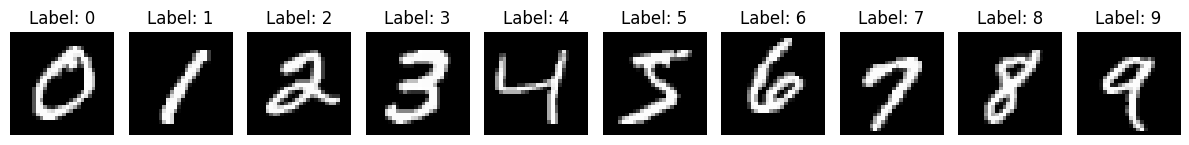

In [2]:
# Print one image of every digit
plt.figure(figsize=(12,3))
for d in range(10):
  idx = np.where(y_train == d)[0][0]
  plt.subplot(1,10,d+1)
  plt.imshow(X_train[idx],cmap='gray')
  plt.title(f"Label: {d}")
  plt.axis('off')

plt.tight_layout()
plt.show()

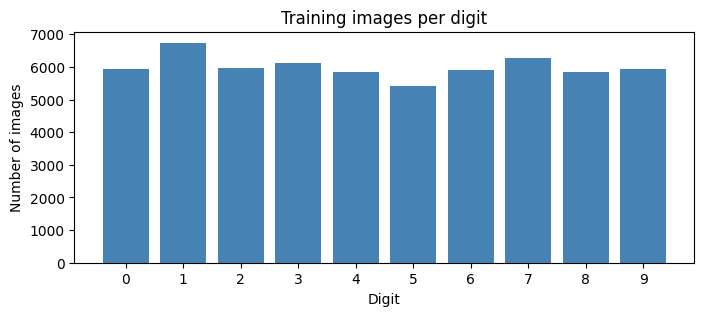

[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [3]:
# check how many images we have for each digit (is the data balanced?)
counts = np.bincount(y_train)

plt.figure(figsize=(8,3))
plt.bar(range(10), counts, color='steelblue')
plt.xticks(range(10))
plt.xlabel('Digit')
plt.ylabel('Number of images')
plt.title('Training images per digit')
plt.show()

print(counts)

Every digit has roughly the same number of images (~6000), so the data is balanced.

## 2. Preprocessing

- Pixel values are 0-255, so we divide by 255 to make them 0-1.
- ANN and SVM need a flat list of 784 numbers for each image.
- CNNs need the shape 28 x 28 x 1 (the 1 is the grayscale channel).
- All 4 models use the **same** data, so the comparison is fair.

In [4]:
# flatten 28x28 into 784 and normalization (for ANN and SVM)
X_train_flat = X_train.reshape(X_train.shape[0],784)/255.0
X_test_flat = X_test.reshape(X_test.shape[0],784)/255.0

# for CNNs keep the image shape and add 1 channel
X_train_cnn = X_train_flat.reshape(-1,28,28,1)
X_test_cnn = X_test_flat.reshape(-1,28,28,1)

print(X_train_flat.shape)
print(X_train_cnn.shape)

(60000, 784)
(60000, 28, 28, 1)


In [5]:
# dictionary to store results of all the models
results = {}

# small function to calculate and store the results (so we dont repeat the code 4 times)
def save_result(name, preds, train_time, pred_time):
  results[name] = {
      'accuracy': accuracy_score(y_test, preds),
      'f1': f1_score(y_test, preds, average='macro'),
      'train_time': train_time,
      'pred_time': pred_time,
      'preds': preds
  }
  print(f"{name} -> Accuracy: {results[name]['accuracy']:.4f}, F1: {results[name]['f1']:.4f}")
  print(f"Training time: {train_time:.1f} sec, Prediction time: {pred_time:.2f} sec")

## 3. Model 1 : ANN

The image is flattened, so the ANN does not know which pixels are neighbours.

In [6]:
ann = Sequential([
  Input(shape=(784,)),
  Dense(128, activation='relu'),
  Dense(64, activation='relu'),
  Dense(10, activation='softmax')
])

ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
ann.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# mini-batch training (batch size 64), 10% of train data is used for validation
start = time.time()
ann_history = ann.fit(X_train_flat, y_train, epochs=5, batch_size=64, validation_split=0.1)
ann_train_time = time.time() - start

# predict on the test images
start = time.time()
ann_probs = ann.predict(X_test_flat, verbose=0)
ann_pred_time = time.time() - start

ann_preds = np.argmax(ann_probs, axis=1)
save_result('ANN', ann_preds, ann_train_time, ann_pred_time)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9150 - loss: 0.2954 - val_accuracy: 0.9645 - val_loss: 0.1209
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9631 - loss: 0.1236 - val_accuracy: 0.9693 - val_loss: 0.1019
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9751 - loss: 0.0845 - val_accuracy: 0.9718 - val_loss: 0.0978
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9816 - loss: 0.0617 - val_accuracy: 0.9730 - val_loss: 0.0933
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9862 - loss: 0.0464 - val_accuracy: 0.9750 - val_loss: 0.0872
ANN -> Accuracy: 0.9738, F1: 0.9735
Training time: 29.1 sec, Prediction time: 0.81 sec


## 4. Model 2 : CNN

A CNN uses small filters (3x3) that slide over the image and pick up edges and curves.
Max pooling makes the image smaller so only the important parts stay.
Then the output is flattened and sent to the Dense layers for the final decision.

In [8]:
cnn = Sequential([
  Input(shape=(28,28,1)),
  Conv2D(32, (3,3), activation='relu'),
  MaxPooling2D((2,2)),
  Conv2D(64, (3,3), activation='relu'),
  MaxPooling2D((2,2)),
  Flatten(),
  Dense(128, activation='relu'),
  Dense(10, activation='softmax')
])

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

start = time.time()
cnn_history = cnn.fit(X_train_cnn, y_train, epochs=5, batch_size=64, validation_split=0.1)
cnn_train_time = time.time() - start

start = time.time()
cnn_probs = cnn.predict(X_test_cnn, verbose=0)
cnn_pred_time = time.time() - start

cnn_preds = np.argmax(cnn_probs, axis=1)
save_result('CNN', cnn_preds, cnn_train_time, cnn_pred_time)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 55ms/step - accuracy: 0.9484 - loss: 0.1715 - val_accuracy: 0.9860 - val_loss: 0.0512
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 57ms/step - accuracy: 0.9850 - loss: 0.0501 - val_accuracy: 0.9878 - val_loss: 0.0416
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 54ms/step - accuracy: 0.9898 - loss: 0.0337 - val_accuracy: 0.9903 - val_loss: 0.0360
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 54ms/step - accuracy: 0.9932 - loss: 0.0228 - val_accuracy: 0.9887 - val_loss: 0.0396
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9948 - loss: 0.0164 - val_accuracy: 0.9900 - val_loss: 0.0386
CNN -> Accuracy: 0.9890, F1: 0.9889
Training time: 340.4 sec, Prediction time: 2.75 sec


## 5. Model 3 : Improved CNN

This is the same CNN as before, but with 2 extra techniques to make it better:

- **Batch Normalization :** keeps the numbers flowing through the network in a nice range, so training is faster and more stable.
- **Dropout :** randomly switches off some neurons during training, so the network does not just memorize the training images (doesnt overfit).

In [10]:
icnn = Sequential([
  Input(shape=(28,28,1)),
  Conv2D(32, (3,3), activation='relu'),
  BatchNormalization(),
  MaxPooling2D((2,2)),
  Dropout(0.25),
  Conv2D(64, (3,3), activation='relu'),
  BatchNormalization(),
  MaxPooling2D((2,2)),
  Dropout(0.25),
  Flatten(),
  Dense(128, activation='relu'),
  Dropout(0.5),
  Dense(10, activation='softmax')
])

icnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

In [11]:
icnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

start = time.time()
icnn_history = icnn.fit(X_train_cnn, y_train, epochs=5, batch_size=64, validation_split=0.1)
icnn_train_time = time.time() - start

start = time.time()
icnn_probs = icnn.predict(X_test_cnn, verbose=0)
icnn_pred_time = time.time() - start

icnn_preds = np.argmax(icnn_probs, axis=1)
save_result('Improved CNN', icnn_preds, icnn_train_time, icnn_pred_time)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 77s 89ms/step - accuracy: 0.8999 - loss: 0.3357 - val_accuracy: 0.9868 - val_loss: 0.0477
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 74s 88ms/step - accuracy: 0.9621 - loss: 0.1299 - val_accuracy: 0.9880 - val_loss: 0.0451
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 88ms/step - accuracy: 0.9714 - loss: 0.0965 - val_accuracy: 0.9892 - val_loss: 0.0386
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 85s 91ms/step - accuracy: 0.9745 - loss: 0.0879 - val_accuracy: 0.9900 - val_loss: 0.0351
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 88ms/step - accuracy: 0.9779 - loss: 0.0768 - val_accuracy: 0.9908 - val_loss: 0.0372
Improved CNN -> Accuracy: 0.9906, F1: 0.9905
Training time: 397.6 sec, Prediction time: 3.36 sec


## 6. Model 4 : SVM (baseline)

SVM is not deep learning, it is a normal machine learning model. We use it only as a **baseline**, to check if deep learning is really better.
It draws boundaries between the digit classes (the RBF kernel can draw curved boundaries).
SVM is very slow on big data, so we train it on only the **first 10,000** training images.
The testing is still done on all 10,000 test images.

In [12]:
svm = SVC(kernel='rbf', C=10, gamma='scale')

start = time.time()
svm.fit(X_train_flat[:10000], y_train[:10000])
svm_train_time = time.time() - start

start = time.time()
svm_preds = svm.predict(X_test_flat)
svm_pred_time = time.time() - start

save_result('SVM', svm_preds, svm_train_time, svm_pred_time)

SVM -> Accuracy: 0.9684, F1: 0.9682
Training time: 11.9 sec, Prediction time: 37.66 sec


## 7. Comparison of all models

In [13]:
# table of results
table = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy (%)': [round(r['accuracy']*100, 2) for r in results.values()],
    'F1 Score (%)': [round(r['f1']*100, 2) for r in results.values()],
    'Training Time (s)': [round(r['train_time'], 1) for r in results.values()],
    'Prediction Time (s)': [round(r['pred_time'], 2) for r in results.values()]
})
table = table.sort_values('Accuracy (%)', ascending=False)
print(table.to_string(index=False))

       Model  Accuracy (%)  F1 Score (%)  Training Time (s)  Prediction Time (s)
Improved CNN         99.06         99.05              397.6                 3.36
         CNN         98.90         98.89              340.4                 2.75
         ANN         97.38         97.35               29.1                 0.81
         SVM         96.84         96.82               11.9                37.66


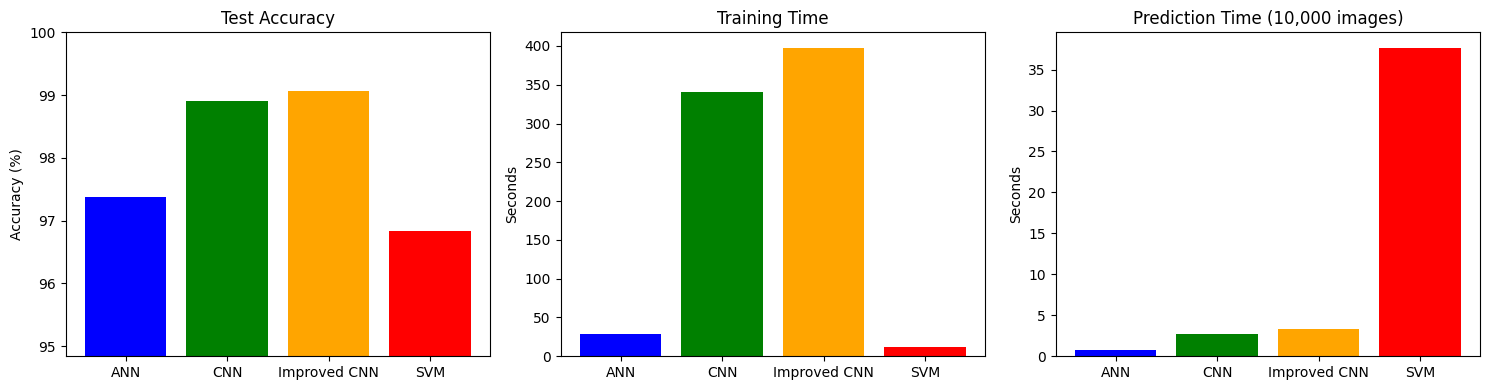

In [14]:
names = list(results.keys())
colors = ['blue','green','orange','red']

accs = [results[n]['accuracy']*100 for n in names]
train_times = [results[n]['train_time'] for n in names]
pred_times = [results[n]['pred_time'] for n in names]

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.bar(names, accs, color=colors)
plt.ylim(min(accs)-2, 100)
plt.ylabel('Accuracy (%)')
plt.title('Test Accuracy')

plt.subplot(1,3,2)
plt.bar(names, train_times, color=colors)
plt.ylabel('Seconds')
plt.title('Training Time')

plt.subplot(1,3,3)
plt.bar(names, pred_times, color=colors)
plt.ylabel('Seconds')
plt.title('Prediction Time (10,000 images)')

plt.tight_layout()
plt.show()

### Loss and accuracy curves (ANN vs CNN vs Improved CNN)

Only the 3 deep learning models have curves because they learn epoch by epoch.
The solid line is training and the dashed line is validation.

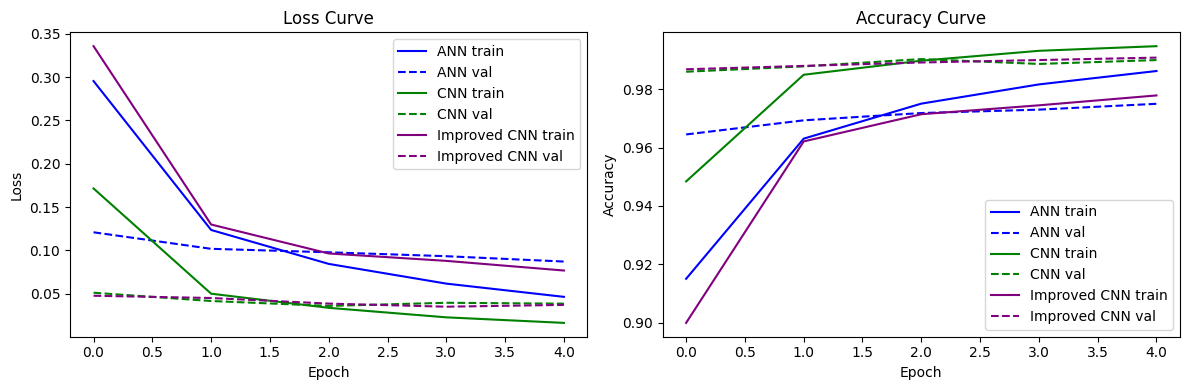

In [15]:
histories = {'ANN': ann_history, 'CNN': cnn_history, 'Improved CNN': icnn_history}
line_colors = {'ANN': 'blue', 'CNN': 'green', 'Improved CNN': 'purple'}

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
for name, h in histories.items():
  plt.plot(h.history['loss'], color=line_colors[name], label=name + ' train')
  plt.plot(h.history['val_loss'], color=line_colors[name], linestyle='--', label=name + ' val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()

plt.subplot(1,2,2)
for name, h in histories.items():
  plt.plot(h.history['accuracy'], color=line_colors[name], label=name + ' train')
  plt.plot(h.history['val_accuracy'], color=line_colors[name], linestyle='--', label=name + ' val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Curve')
plt.legend()

plt.tight_layout()
plt.show()

### Confusion matrix of all models

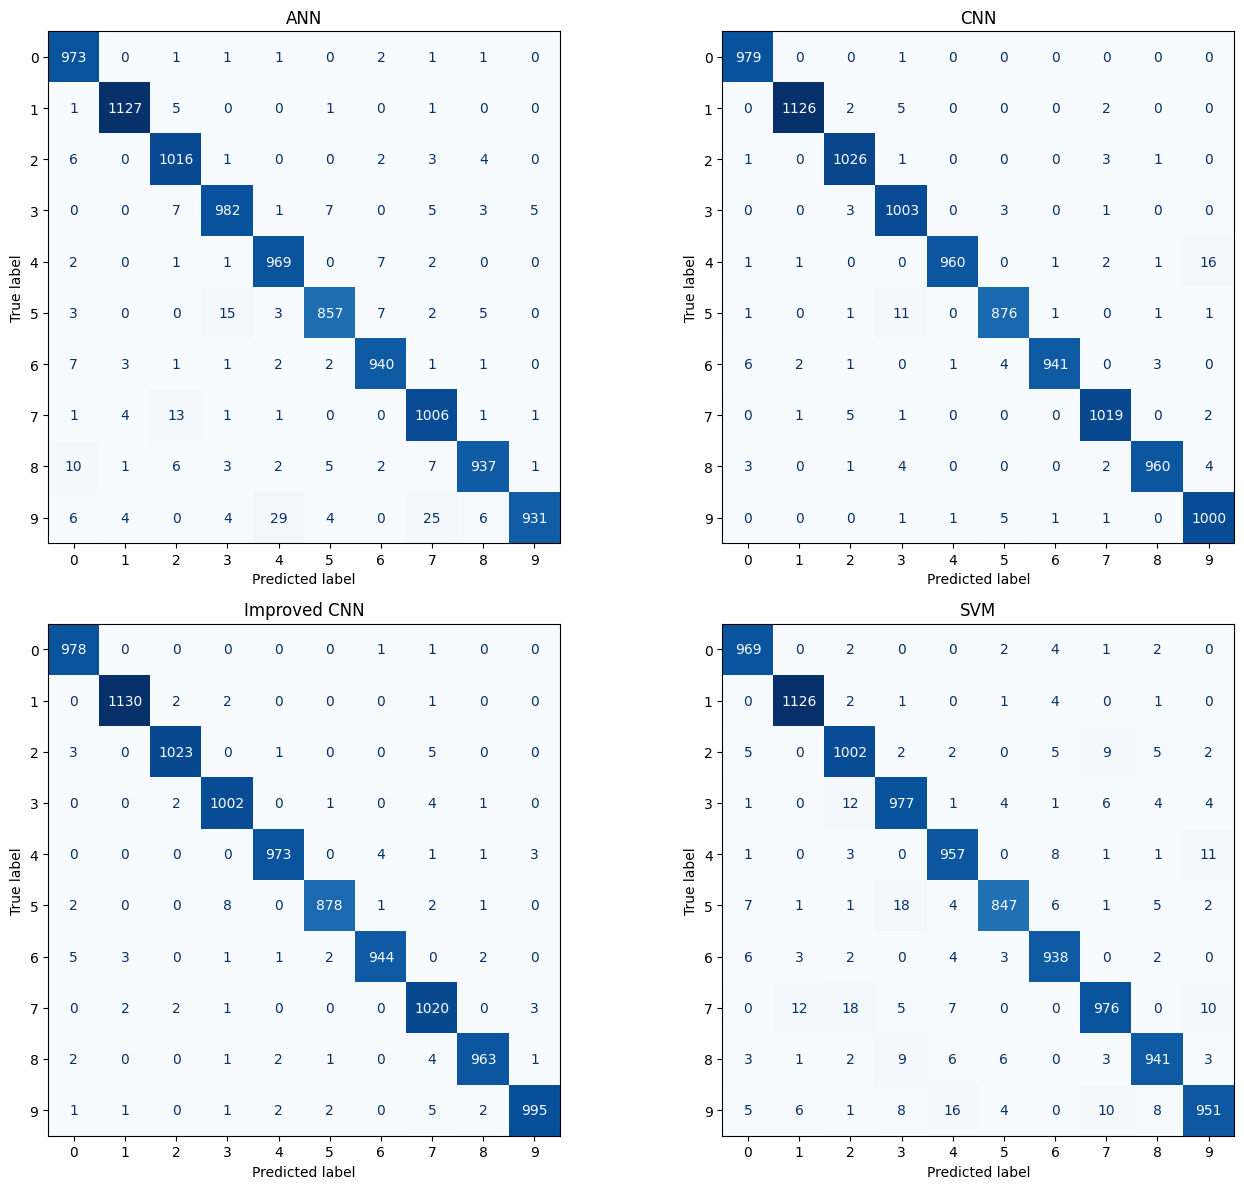

In [16]:
plt.figure(figsize=(14,12))
for i, name in enumerate(names):
  ax = plt.subplot(2,2,i+1)
  ConfusionMatrixDisplay.from_predictions(y_test, results[name]['preds'], cmap='Blues', ax=ax, colorbar=False)
  ax.set_title(name)

plt.tight_layout()
plt.show()

### Accuracy of each digit

This shows which digits are easy and which are hard for each model.

           ANN    CNN  Improved CNN    SVM
Digit 0  99.29  99.90         99.80  98.88
Digit 1  99.30  99.21         99.56  99.21
Digit 2  98.45  99.42         99.13  97.09
Digit 3  97.23  99.31         99.21  96.73
Digit 4  98.68  97.76         99.08  97.45
Digit 5  96.08  98.21         98.43  94.96
Digit 6  98.12  98.23         98.54  97.91
Digit 7  97.86  99.12         99.22  94.94
Digit 8  96.20  98.56         98.87  96.61
Digit 9  92.27  99.11         98.61  94.25


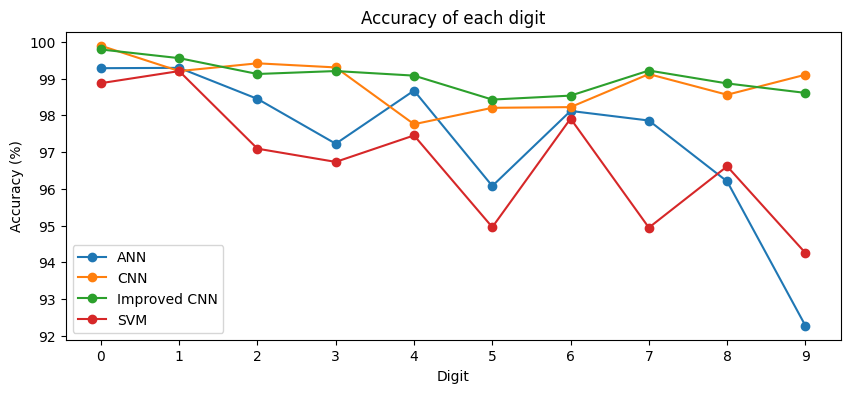

In [17]:
digit_acc = {}
for name in names:
  preds = results[name]['preds']
  acc_list = []
  for d in range(10):
    mask = (y_test == d)
    acc_list.append(np.mean(preds[mask] == d) * 100)
  digit_acc[name] = acc_list

digit_table = pd.DataFrame(digit_acc, index=[f"Digit {d}" for d in range(10)]).round(2)
print(digit_table)

plt.figure(figsize=(10,4))
for name in names:
  plt.plot(range(10), digit_acc[name], marker='o', label=name)
plt.xticks(range(10))
plt.xlabel('Digit')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy of each digit')
plt.legend()
plt.show()

## 8. Best model

In [18]:
# model with the highest test accuracy
best_name = max(results, key=lambda n: results[n]['accuracy'])
best_preds = results[best_name]['preds']

print("Best model :", best_name)
print(f"Accuracy   : {results[best_name]['accuracy']*100:.2f} %")
print()
print(classification_report(y_test, best_preds))

Best model : Improved CNN
Accuracy   : 99.06 %

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



### Mistakes of the best model

Improved CNN got 94 out of 10000 images wrong


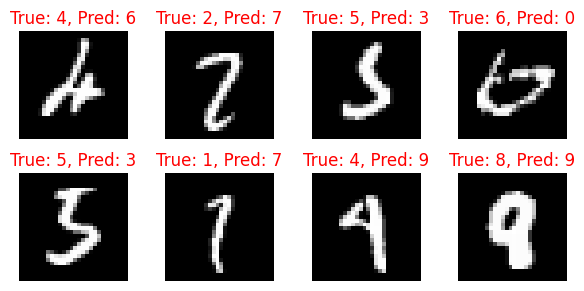

In [20]:
wrong = np.where(best_preds != y_test)[0]
print(f"{best_name} got {len(wrong)} out of {len(y_test)} images wrong")

# 8 wrong images
plt.figure(figsize=(6,3))
for i in range(min(8, len(wrong))):
  idx = wrong[i]
  plt.subplot(2,4,i+1)
  plt.imshow(X_test[idx], cmap='gray')
  plt.title(f"True: {y_test[idx]}, Pred: {best_preds[idx]}", color='red')
  plt.axis('off')

plt.tight_layout()
plt.show()

In [21]:
# which digits are confused the most?
cm = confusion_matrix(y_test, best_preds)
np.fill_diagonal(cm, 0)   # remove the correct predictions

print("Most confused digits:")
for _ in range(3):
  i, j = np.unravel_index(np.argmax(cm), cm.shape)
  print(f"  {i} predicted as {j} : {cm[i,j]} times")
  cm[i,j] = 0

Most confused digits:
  5 predicted as 3 : 8 times
  2 predicted as 7 : 5 times
  6 predicted as 0 : 5 times


### Save the best model

In [22]:
# neural networks are saved with keras, SVM with joblib
if best_name == 'ANN':
  ann.save('best_model.keras')
elif best_name == 'CNN':
  cnn.save('best_model.keras')
elif best_name == 'Improved CNN':
  icnn.save('best_model.keras')
else:
  joblib.dump(svm, 'best_model.joblib')

print(f"{best_name} model saved")

Improved CNN model saved


## 9. Conclusion

The conclusion below is printed from the actual results of this run.

In [24]:
ranked = sorted(results, key=lambda n: results[n]['accuracy'], reverse=True)
fastest_train = min(results, key=lambda n: results[n]['train_time'])
fastest_pred = min(results, key=lambda n: results[n]['pred_time'])

print("Ranking by accuracy:")
for rank, name in enumerate(ranked, 1):
  print(f"  {rank}. {name}  ->  {results[name]['accuracy']*100:.2f} %")

print()
print("Best model             :", ranked[0])
print("Lowest accuracy        :", ranked[-1])
print("Fastest to predict     :", fastest_pred)

Ranking by accuracy:
  1. Improved CNN  ->  99.06 %
  2. CNN  ->  98.90 %
  3. ANN  ->  97.38 %
  4. SVM  ->  96.84 %

Best model             : Improved CNN
Lowest accuracy        : SVM
Fastest to predict     : ANN


**Observation**

1. **ANN** flattens the image into 784 numbers, so it does not know which pixels are next to each other. It still gives good accuracy on MNIST because the digits are clean and centered.

2. **CNN** uses filters and pooling, so it looks at small parts of the image (edges, curves) instead of treating every pixel separately. This is why CNN is made for image data. It takes more time to train than the ANN.

3. **Improved CNN** is the CNN with Batch Normalization and Dropout. These help the model avoid overfitting, which we can check in the curves (gap between the solid train line and the dashed validation line). It takes a bit more time per epoch because of the extra layers. On an easy dataset like MNIST the gain over the basic CNN is small.

4. **SVM** (baseline) does not learn features by itself and becomes very slow when the data is large, so we trained it on only 10,000 images. Its result is good for a normal machine learning model, but it is trained on less data than the others.

**Overall :** Deep learning models (especially the CNNs) give the best accuracy for image data. The SVM baseline shows that normal ML can also work, but it cannot use the full data easily.

**Limitations**
- MNIST images are clean and centered. Real handwriting is messier, so the accuracy can be lower.
- We trained for only 5 epochs and did not tune the settings (learning rate, number of layers, dropout value).
- No data augmentation (rotating or shifting the images) was used.

**Future work**
- Try a harder dataset like Fashion-MNIST or EMNIST.
- Use data augmentation to make the model work on messy handwriting.
- Build a small app where the user draws a digit and the saved best model predicts it.

## 10. Viva Questions

**Q1. What is the convolutional operation?**
A small filter (like 3x3) slides over the image. At each position it multiplies its values with the pixels below it and adds them up. This gives a feature map that shows where a pattern (like an edge) is present.

**Q2. What is pooling?**
Pooling makes the image smaller. In max pooling (2x2) we keep only the biggest value from every 2x2 block. This reduces computation and keeps the important features.

**Q3. Why do we need Flatten?**
Conv and pooling layers give a 2D output, but Dense layers need a 1D list of numbers. Flatten converts the 2D output into one long list.

**Q4. Why is CNN better than ANN for images?**
ANN treats every pixel separately. CNN looks at small neighbouring regions, so it can find edges and shapes.

**Q5. Why did we divide the pixel values by 255?**
To bring the values between 0 and 1. It helps the network learn faster.

**Q6. Why softmax in the last layer?**
It converts the 10 output values into probabilities that add up to 1. The biggest one is the predicted digit.

**Q7. What is the difference between accuracy and F1 score?**
Accuracy is the percentage of correct predictions. F1 score combines precision and recall, and the macro F1 gives equal importance to every digit.

**Q8. What is a confusion matrix?**
A table where rows are the actual digits and columns are the predicted digits. The diagonal is the correct predictions and the other cells are mistakes.

**Q9. What is Dropout and why do we use it?**
Dropout randomly switches off some neurons while training. So the network cannot depend on any single neuron, and it does not memorize the training data (overfitting).

**Q10. What is Batch Normalization?**
It rescales the values coming out of a layer so that they stay in a nice range. This makes training faster and more stable.

**Q11. What is overfitting and how do we see it?**
Overfitting is when the model does very well on training data but worse on new data. In the curves, the training accuracy keeps going up while the validation accuracy stays low or goes down.

**Q12. Why did we use the same data and the same epochs for all models?**
So that the comparison is fair.

**Q13. Why is SVM used in a deep learning project?**
As a baseline. It shows how a normal ML model performs, so we can see how much better the deep learning models are.